# Etapa 5 — Modelo de crédito com e sem gênero (H2)

Projeto SME0828 — Introdução à Ciência de Dados, ICMC/USP.

Semente do código: 444. Reexecute o notebook para atualizar os resultados exibidos.


Treinamos dois modelos para prever a decisão de negação do banco: um recebe a variável `mulher` e o outro não. O HMDA não informa inadimplência; portanto, os modelos aprendem a reproduzir decisões dos bancos, não a estimar o risco real de crédito.

H2 pergunta se o modelo sem gênero ainda prevê taxas de negação diferentes entre mulheres e homens por causa das demais variáveis.

### Bibliotecas

In [1]:
from pathlib import Path
import os
import sys

ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents) if (path / "data").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Abra este notebook dentro do repositório, que deve conter a pasta data/")
os.chdir(ROOT)

SCRIPTS = ROOT / "code" / "scripts"
if str(SCRIPTS) not in sys.path:
    sys.path.insert(0, str(SCRIPTS))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from preparo_hmda import CATEGORICAL_FEATURES, FEATURES_BASE
from modelagem_h2 import (
    AMOSTRA_TESTE,
    ARQUIVO_DADOS,
    PASTA_SAIDA,
    executar_modelagem,
)

BLUE = "#2a78d6"
ORANGE = "#eb6834"
GRAY = "#898781"
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
(ROOT / "figuras").mkdir(parents=True, exist_ok=True)

### 2. Leitura e preparação dos dados

O pipeline compartilhado carrega a amostra, aplica os filtros definidos no protocolo, faz a divisão treino/teste, seleciona hiperparâmetros e ajusta os dois modelos. O mesmo código atende ao notebook e ao script de execução.

In [2]:
resultado_h2 = executar_modelagem(
    caminho_dados=ARQUIVO_DADOS,
    amostra=AMOSTRA_TESTE,
    pasta_saida=PASTA_SAIDA,
)
data = resultado_h2["dados"]
treino = resultado_h2["treino"]
teste = resultado_h2["teste"]
idx_treino = resultado_h2["idx_treino"]
idx_teste = resultado_h2["idx_teste"]
busca = resultado_h2["busca"]
hiperparametros = resultado_h2["hiperparametros"]
modelos = resultado_h2["modelos"]
limiares = resultado_h2["limiares"]

print("Dimensão da amostra:", data.shape)
data.head()

Carregando C:\Users\opedr\OneDrive\Desktop\icd trabalho\hmda-genero-credito\data\amostra_principal.parquet
Base: 1,532,885 linhas | Treino: 1,073,019 | Teste: 459,866
Melhores hiperparâmetros: {'learning_rate': 0.05, 'max_leaf_nodes': 15}

Treinando Gradient Boosting: Com gênero
  AUC-ROC = 0.7859 | PR-AUC = 0.5448 | Brier = 0.0649 | DP prévia = 3.52 p.p. (76.9s)

Treinando Gradient Boosting: Sem gênero
  AUC-ROC = 0.7861 | PR-AUC = 0.5454 | Brier = 0.0648 | DP prévia = 3.77 p.p. (117.7s)

Resultados salvos em C:\Users\opedr\OneDrive\Desktop\icd trabalho\hmda-genero-credito\resultados
Dimensão da amostra: (1532885, 10)


,state_code,income,combined_loan_to_value_ratio,loan_type,dti,applicant_age,negado,mulher,ltv,log_renda
0,TX,65.0,97.000,1,36%-<50%,25-34,0,0,97.000,4.174387
1,CA,178.0,80.000,1,36%-<50%,35-44,0,1,80.000,5.181784
2,CA,61.0,96.500,2,50%-60%,<25,0,0,96.500,4.110874
3,MN,69.0,97.000,1,20%-<30%,25-34,0,1,97.000,4.234107
4,MI,59.0,98.189,2,20%-<30%,<25,0,0,98.189,4.077537


### 3. Atributos

Os modelos usam log da renda, LTV, DTI, tipo de empréstimo, estado e idade. O modelo com gênero também recebe `mulher`. Excluímos variáveis definidas após a decisão, como motivo da negação e taxa de juros, para evitar vazamento.

`HistGradientBoostingClassifier` aceita colunas categóricas sem one-hot encoding, desde que sejam do tipo `category`.

In [3]:
categoricas = CATEGORICAL_FEATURES
atributos_sem_genero = FEATURES_BASE
atributos_com_genero = ["mulher"] + FEATURES_BASE

data[atributos_com_genero + ["negado"]].head()

,mulher,log_renda,ltv,dti,loan_type,state_code,applicant_age,negado
0,0,4.174387,97.000,36%-<50%,1,TX,25-34,0
1,1,5.181784,80.000,36%-<50%,1,CA,35-44,0
2,0,4.110874,96.500,50%-60%,2,CA,<25,0
3,1,4.234107,97.000,20%-<30%,1,MN,25-34,0
4,0,4.077537,98.189,20%-<30%,2,MI,<25,0


### 4. Treino e teste

Dividimos os dados em 70% para treino e 30% para teste, estratificando por negação e gênero. Os dois modelos usam a mesma divisão.

In [4]:
y_treino = treino["negado"].to_numpy()
y_teste = teste["negado"].to_numpy()

print(
    f"Treino: {treino.shape} - negados: {y_treino.mean():.1%} "
    f"- mulheres: {treino['mulher'].mean():.1%}"
)
print(f"Teste:  {teste.shape} - negados: {y_teste.mean():.1%}")

Treino: (1073019, 10) - negados: 10.5% - mulheres: 38.9%
Teste:  (459866, 10) - negados: 10.5%


### 5. Gradient Boosting e hiperparâmetros

O Gradient Boosting treina árvores em sequência. O pipeline compartilhado ajusta `HistGradientBoostingClassifier` e escolhe os hiperparâmetros por AUC-ROC, com validação cruzada estratificada. A busca usa até 100 mil pedidos do treino; os parâmetros escolhidos são iguais nos dois modelos.

In [5]:
print("Melhores hiperparâmetros:", busca.best_params_)
print(f"AUC na validação cruzada: {busca.best_score_:.4f}")
pd.DataFrame(busca.cv_results_)[["params", "mean_test_score", "std_test_score"]].round(4)

Melhores hiperparâmetros: {'learning_rate': 0.05, 'max_leaf_nodes': 15}
AUC na validação cruzada: 0.7764


,params,mean_test_score,std_test_score
0,"{'learning_rate': 0.05, 'max_leaf_nodes': 15}",0.7764,0.0061
1,"{'learning_rate': 0.05, 'max_leaf_nodes': 31}",0.7756,0.0052
2,"{'learning_rate': 0.05, 'max_leaf_nodes': 63}",0.7737,0.0052
3,"{'learning_rate': 0.1, 'max_leaf_nodes': 15}",0.7758,0.0056
4,"{'learning_rate': 0.1, 'max_leaf_nodes': 31}",0.7755,0.0061
5,"{'learning_rate': 0.1, 'max_leaf_nodes': 63}",0.7721,0.0053


### 6. Limiar de decisão

O modelo estima uma probabilidade de negação. Para convertê-la em classe, escolhemos no treino um limiar que iguala a taxa prevista à taxa observada. Usamos probabilidades de validação cruzada para não ajustar o limiar no teste.

In [6]:
print("Modelos treinados pelo pipeline compartilhado.")
pd.DataFrame({"limiar_cv_treino": limiares})

Modelos treinados pelo pipeline compartilhado.


,limiar_cv_treino
Com gênero,0.143908
Sem gênero,0.143652


### 7. Modelo de comparação

Comparamos o Gradient Boosting com uma regressão logística sem gênero, usando one-hot encoding nas categorias e `StandardScaler` nas variáveis numéricas.

In [7]:
logistica = Pipeline([
    ("preparo", ColumnTransformer([
        ("num", StandardScaler(), ["log_renda", "ltv"]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas),
    ])),
    ("modelo", LogisticRegression(max_iter=1000)),
])
logistica.fit(treino[atributos_sem_genero], y_treino)
print("Regressão logística ajustada para comparação.")

Regressão logística ajustada para comparação.


### 8. Avaliação no teste

Como as classes são desbalanceadas, reportamos AUC-ROC, PR-AUC e Brier score. A AUC mede a separação entre aprovados e negados; a PR-AUC é útil para a classe menos frequente; o Brier score mede o erro das probabilidades (quanto menor, melhor).

In [8]:
probas = {
    "GB com gênero": resultado_h2["probabilidades"]["Com gênero"],
    "GB sem gênero": resultado_h2["probabilidades"]["Sem gênero"],
    "Logística sem gênero": logistica.predict_proba(teste[atributos_sem_genero])[:, 1],
}

desempenho = pd.DataFrame({
    nome: {
        "AUC-ROC": roc_auc_score(y_teste, proba),
        "PR-AUC": average_precision_score(y_teste, proba),
        "Brier": brier_score_loss(y_teste, proba),
    }
    for nome, proba in probas.items()
}).T
desempenho.round(4)

,AUC-ROC,PR-AUC,Brier
GB com gênero,0.7859,0.5448,0.0649
GB sem gênero,0.7861,0.5454,0.0648
Logística sem gênero,0.7399,0.4729,0.0720


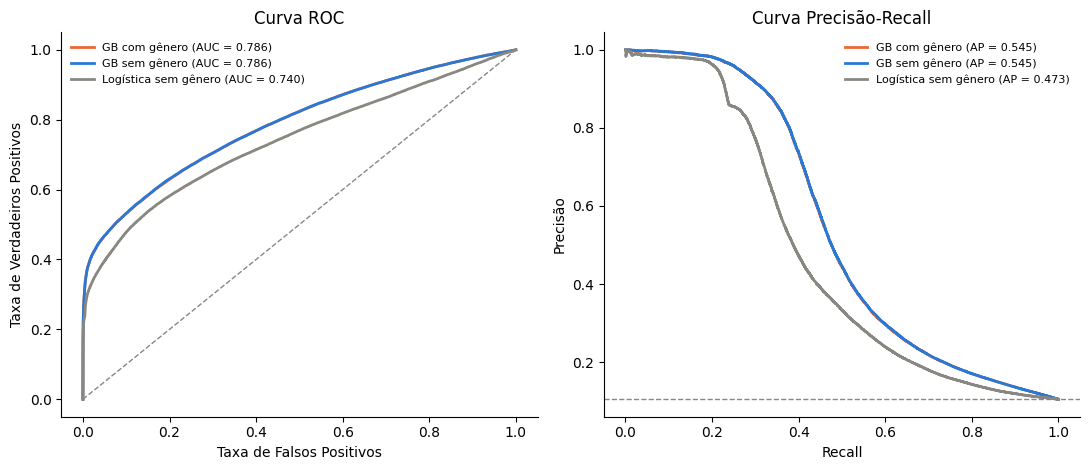

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
cores = {"GB com gênero": ORANGE, "GB sem gênero": BLUE, "Logística sem gênero": GRAY}

for nome, p in probas.items():
    fpr, tpr, _ = roc_curve(y_teste, p)
    axes[0].plot(fpr, tpr, color=cores[nome], linewidth=2, label=f"{nome} (AUC = {roc_auc_score(y_teste, p):.3f})")
    precisao, recall, _ = precision_recall_curve(y_teste, p)
    axes[1].plot(recall, precisao, color=cores[nome], linewidth=2, label=f"{nome} (AP = {average_precision_score(y_teste, p):.3f})")

axes[0].plot([0, 1], [0, 1], color=GRAY, linestyle="--", linewidth=1)
axes[0].set_xlabel("Taxa de Falsos Positivos")
axes[0].set_ylabel("Taxa de Verdadeiros Positivos")
axes[0].set_title("Curva ROC")
axes[1].axhline(y_teste.mean(), color=GRAY, linestyle="--", linewidth=1)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisão")
axes[1].set_title("Curva Precisão-Recall")
for ax in axes:
    ax.legend(frameon=False, fontsize=8)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig("figuras/etapa_05_h2_curvas_roc_pr.png", dpi=300)
plt.show()

As curvas comparam os dois modelos de Gradient Boosting e a regressão logística de referência. Em seguida, aplicamos os limiares escolhidos no treino e examinamos as matrizes de confusão.

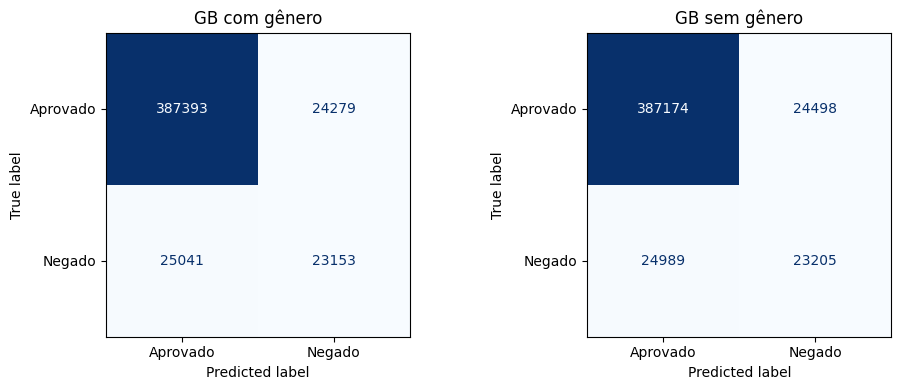

Gradient Boosting sem gênero:
              precision    recall  f1-score   support

    Aprovado       0.94      0.94      0.94    411672
      Negado       0.49      0.48      0.48     48194

    accuracy                           0.89    459866
   macro avg       0.71      0.71      0.71    459866
weighted avg       0.89      0.89      0.89    459866



In [10]:
pred_com = resultado_h2["predicoes"]["Com gênero"]
pred_sem = resultado_h2["predicoes"]["Sem gênero"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, nome in zip(axes, [pred_com, pred_sem], ["Com gênero", "Sem gênero"]):
    ConfusionMatrixDisplay(confusion_matrix(y_teste, pred), display_labels=["Aprovado", "Negado"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"GB {nome.lower()}")
plt.tight_layout()
plt.show()

print("Gradient Boosting sem gênero:")
print(classification_report(y_teste, pred_sem, target_names=["Aprovado", "Negado"]))

### 9. Taxa de negação por gênero

Comparamos as decisões reais dos bancos com as previsões de cada modelo, separadas por gênero. A Etapa E calcula os intervalos de confiança e as demais métricas de equidade.

Diferença mulheres - homens (p.p.):
Real (bancos)    1.41
GB com gênero    3.52
GB sem gênero    3.77
dtype: float64


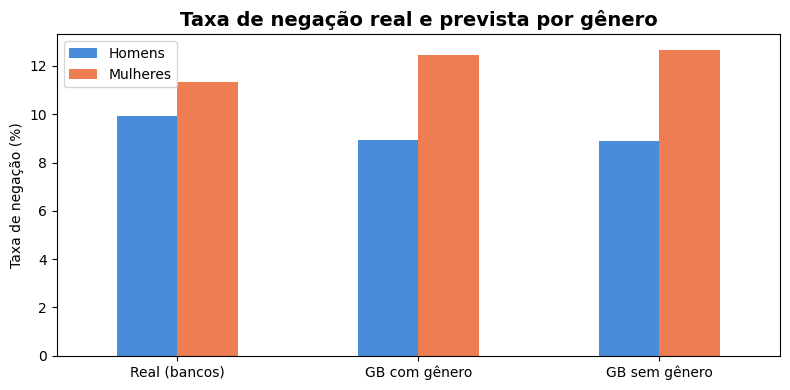

In [11]:
mulher = teste["mulher"].values == 1

taxas = pd.DataFrame({
    "Real (bancos)": [y_teste[~mulher].mean(), y_teste[mulher].mean()],
    "GB com gênero": [pred_com[~mulher].mean(), pred_com[mulher].mean()],
    "GB sem gênero": [pred_sem[~mulher].mean(), pred_sem[mulher].mean()],
}, index=["Homens", "Mulheres"])

print("Diferença mulheres - homens (p.p.):")
print((100 * (taxas.loc["Mulheres"] - taxas.loc["Homens"])).round(2))

(100 * taxas.T).plot(kind="bar", color=[BLUE, ORANGE], alpha=0.85, rot=0, figsize=(8, 4))
plt.ylabel("Taxa de negação (%)")
plt.title("Taxa de negação real e prevista por gênero", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("figuras/etapa_05_h2_taxa_prevista_genero.png", dpi=300)
plt.show()

### 10. Salvamento dos resultados

Salvamos as métricas, as previsões no teste e os modelos em `resultados/`. As Etapas E e F usam esses arquivos; os artefatos grandes ficam fora do Git.

In [12]:
caminho_comparacao = PASTA_SAIDA / "etapa_05_h2_comparacao_modelos.md"
caminho_comparacao.write_text(desempenho.round(4).to_markdown(), encoding="utf-8")
print("Artefatos H2 salvos pelo pipeline compartilhado em resultados/.")
print(f"Comparação com a regressão logística: {caminho_comparacao}")
desempenho.round(4)

Artefatos H2 salvos pelo pipeline compartilhado em resultados/.
Comparação com a regressão logística: C:\Users\opedr\OneDrive\Desktop\icd trabalho\hmda-genero-credito\resultados\etapa_05_h2_comparacao_modelos.md


,AUC-ROC,PR-AUC,Brier
GB com gênero,0.7859,0.5448,0.0649
GB sem gênero,0.7861,0.5454,0.0648
Logística sem gênero,0.7399,0.4729,0.0720


### 11. Exemplo de previsão

O exemplo abaixo calcula a probabilidade de negação para um pedido. Se a probabilidade alcançar o limiar escolhido, o modelo classifica o pedido como negado.

Altere as características do exemplo para comparar perfis: renda anual em milhares de dólares, LTV, faixa de DTI, tipo de empréstimo, estado e faixa etária.

In [13]:
# ---- Dados do pedido (altere aqui) ----
renda = 60
ltv = 95
dti = "36%-<50%"
tipo = "1"
estado = "TX"
idade = "35-44"

pedido = pd.DataFrame({
    "log_renda": [np.log(renda)],
    "ltv": [ltv],
    "dti": [dti],
    "loan_type": [tipo],
    "state_code": [estado],
    "applicant_age": [idade],
})

# As categorias precisam ser as mesmas usadas no treino;
# caso contrário, o modelo interpretaria os valores de forma errada.
for col in categoricas:
    pedido[col] = pd.Categorical(pedido[col], categories=treino[col].cat.categories)

probabilidade = modelos["Sem gênero"].predict_proba(pedido[atributos_sem_genero])[0, 1]

print(f"Probabilidade de negação: {probabilidade:.1%}  (limiar: {limiares['Sem gênero']:.1%})")
print("Resultado:", "NEGADO" if probabilidade >= limiares["Sem gênero"] else "APROVADO")

Probabilidade de negação: 15.9%  (limiar: 14.4%)
Resultado: NEGADO


#### O mesmo pedido com gêneros diferentes

No modelo com gênero, avaliamos o mesmo perfil duas vezes, alterando apenas `mulher`. A diferença entre as probabilidades mostra o efeito dessa variável dentro do modelo.

In [14]:
pedido_homem = pedido.copy()
pedido_homem.insert(0, "mulher", 0)
pedido_mulher = pedido.copy()
pedido_mulher.insert(0, "mulher", 1)

p_homem = modelos["Com gênero"].predict_proba(pedido_homem[atributos_com_genero])[0, 1]
p_mulher = modelos["Com gênero"].predict_proba(pedido_mulher[atributos_com_genero])[0, 1]
limiar_com = limiares["Com gênero"]

print(f"Homem:   {p_homem:.2%} de chance de negação -> {'NEGADO' if p_homem >= limiar_com else 'APROVADO'}")
print(f"Mulher:  {p_mulher:.2%} de chance de negação -> {'NEGADO' if p_mulher >= limiar_com else 'APROVADO'}")
print(f"Diferença (mulher - homem): {100 * (p_mulher - p_homem):+.2f} p.p.")

Homem:   15.76% de chance de negação -> NEGADO
Mulher:  15.37% de chance de negação -> NEGADO
Diferença (mulher - homem): -0.39 p.p.


Também comparamos vários perfis, do menor ao maior risco estimado.

In [15]:
perfis = pd.DataFrame({
    "Perfil": ["Renda alta, pouca dívida", "Renda média", "Renda média, LTV alto", "Renda baixa, muita dívida", "DTI acima de 60%"],
    "log_renda": np.log([150, 80, 80, 40, 60]),
    "ltv": [70, 90, 100, 97, 95],
    "dti": ["<20%", "30%-<36%", "36%-<50%", "50%-60%", ">60%"],
    "loan_type": ["1", "1", "1", "2", "1"],
    "state_code": ["CA", "TX", "TX", "FL", "NY"],
    "applicant_age": ["35-44", "35-44", "25-34", "25-34", "45-54"],
})
for col in categoricas:
    perfis[col] = pd.Categorical(perfis[col], categories=treino[col].cat.categories)

simulacao = perfis[["Perfil"]].copy()
for nome_genero, valor in [("Homem", 0), ("Mulher", 1)]:
    entrada = perfis.copy()
    entrada["mulher"] = valor
    simulacao[f"Prob. {nome_genero} (%)"] = 100 * modelos["Com gênero"].predict_proba(entrada[atributos_com_genero])[:, 1]

simulacao["Diferença (p.p.)"] = simulacao["Prob. Mulher (%)"] - simulacao["Prob. Homem (%)"]
simulacao["Decisão homem"] = np.where(simulacao["Prob. Homem (%)"] >= 100 * limiar_com, "Negado", "Aprovado")
simulacao["Decisão mulher"] = np.where(simulacao["Prob. Mulher (%)"] >= 100 * limiar_com, "Negado", "Aprovado")
simulacao.round(2)

,Perfil,Prob. Homem (%),Prob. Mulher (%),Diferença (p.p.),Decisão homem,Decisão mulher
0,"Renda alta, pouca dívida",7.55,7.49,-0.06,Aprovado,Aprovado
1,Renda média,8.72,8.46,-0.25,Aprovado,Aprovado
2,"Renda média, LTV alto",10.97,10.97,-0.01,Aprovado,Aprovado
3,"Renda baixa, muita dívida",24.75,25.14,0.39,Negado,Negado
4,DTI acima de 60%,96.57,96.67,0.10,Negado,Negado


Para o mesmo perfil, mudar apenas o gênero altera a probabilidade em menos de 0,11 p.p., sem mudar nenhuma decisão. Já a diferença de 3,4 p.p. nas taxas previstas vem dos perfis distintos entre os grupos. Renda, idade e tipo de empréstimo ajudam a explicar essa diferença; a Etapa F examina essas variáveis.

### Conclusão

- O Gradient Boosting alcança AUC de 0,787 e PR-AUC de 0,544, acima da regressão logística (0,740 e 0,472).
- Incluir gênero quase não altera a AUC: 0,7868 com gênero e 0,7867 sem gênero.
- Sem gênero, o modelo prevê 3,7 p.p. mais negações para mulheres. Essa diferença supera a diferença observada nos bancos (1,4 p.p.).
- As outras variáveis carregam informação associada ao gênero e mantêm a disparidade nas previsões.
- A Etapa B não encontrou diferença significativa após controles; a Etapa E detalha como o limiar transforma diferenças nas probabilidades em diferenças nas decisões.